<a href="https://colab.research.google.com/github/qnsebas23/Probabilidad-y-Estadistica/blob/main/unidad5/Practica_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Probablidad y estadistica

#Unidad 5

##Practica Final: Regresión lineal y correlación

Docente: Jose Gabriel Rodriguez Rivas

Alumno: Sebastian Quiñones Nevarez

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats


In [6]:
# Configuración visual profesional
sns.set_theme(style="whitegrid", context="notebook")

archivos = ['grupo1.csv', 'grupo2.csv', 'grupo3.csv']
datasets = {}

print("--- AUDITORÍA INICIAL DE LOS CONJUNTOS DE DATOS ---\n")
for archivo in archivos:
    df = pd.read_csv(archivo)
    datasets[archivo] = df
    print(f"Archivo: {archivo} | Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
    print(f"Valores nulos: {df.isnull().sum().to_dict()} | Filas duplicadas: {df.duplicated().sum()}")
    display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'}))
    print("-" * 75)

--- AUDITORÍA INICIAL DE LOS CONJUNTOS DE DATOS ---

Archivo: grupo1.csv | Filas: 50, Columnas: 2
Valores nulos: {'HorasEstudio': 0, 'Calificacion': 0} | Filas duplicadas: 0


,count,mean,std,min,median,max
HorasEstudio,50.0,14.3520,4.219174,3.79,14.60,20.0
Calificacion,50.0,83.7882,7.833890,68.46,84.49,100.0


---------------------------------------------------------------------------
Archivo: grupo2.csv | Filas: 50, Columnas: 2
Valores nulos: {'HorasEstudio': 0, 'Calificacion': 0} | Filas duplicadas: 1


,count,mean,std,min,median,max
HorasEstudio,50.0,14.352,4.219174,3.79,14.60,20.0
Calificacion,50.0,75.912,20.668922,26.10,78.55,99.0


---------------------------------------------------------------------------
Archivo: grupo3.csv | Filas: 50, Columnas: 2
Valores nulos: {'HorasEstudio': 0, 'Calificacion': 0} | Filas duplicadas: 1


,count,mean,std,min,median,max
HorasEstudio,50.0,14.352,4.219174,3.79,14.60,20.0
Calificacion,50.0,75.968,23.668867,15.00,84.95,99.0


---------------------------------------------------------------------------


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
resumen_resultados = []

for archivo, df in datasets.items():
    print("=" * 80)
    print(f"MODELO DE REGRESIÓN LINEAL E INFERENCIA ESTADÍSTICA: {archivo.upper()}")
    print("=" * 80)

    X = df[['HorasEstudio']]
    y = df['Calificacion']

    # 1. Ajuste con scikit-learn (para métricas predictivas)
    modelo_sk = LinearRegression()
    modelo_sk.fit(X, y)
    y_pred = modelo_sk.predict(X)

    pendiente = modelo_sk.coef_[0]
    intercepto = modelo_sk.intercept_
    r, p_valor = stats.pearsonr(df['HorasEstudio'], y)
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    mae = mean_absolute_error(y, y_pred)

    # 2. Ajuste con statsmodels OLS (para intervalos de confianza, error estándar y prueba F)
    X_sm = sm.add_constant(df['HorasEstudio'])
    modelo_ols = sm.OLS(y, X_sm).fit()
    print(modelo_ols.summary())

    # Guardar métricas en lista resumen
    resumen_resultados.append({
        'Grupo': archivo,
        'Ecuación': f"ŷ = {pendiente:.4f}x + {intercepto:.4f}",
        'Pendiente (β1)': round(pendiente, 4),
        'Intercepto (β0)': round(intercepto, 4),
        'Pearson (r)': round(r, 4),
        'R²': round(r2, 4),
        'RMSE (Error)': round(rmse, 4),
        'Valor p': f"{p_valor:.4e}",
        'Significativo (α=0.05)': 'Sí' if p_valor < 0.05 else 'No'
    })

print("\n" + "=" * 80)
print("TABLA COMPARATIVA GENERAL DE LOS TRES GRUPOS")
print("=" * 80)
df_resumen = pd.DataFrame(resumen_resultados)
display(df_resumen)

MODELO DE REGRESIÓN LINEAL E INFERENCIA ESTADÍSTICA: GRUPO1.CSV
                            OLS Regression Results                            
Dep. Variable:           Calificacion   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.018
Method:                 Least Squares   F-statistic:                    0.1572
Date:                Fri, 13 Nov 2026   Prob (F-statistic):              0.694
Time:                        05:11:57   Log-Likelihood:                -173.28
No. Observations:                  50   AIC:                             350.6
Df Residuals:                      48   BIC:                             354.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

,Grupo,Ecuación,Pendiente (β1),Intercepto (β0),Pearson (r),R²,RMSE (Error),Valor p,Significativo (α=0.05)
0,grupo1.csv,ŷ = -0.1061x + 85.3107,-0.1061,85.3107,-0.0571,0.0033,7.7425,6.9351e-01,No
1,grupo2.csv,ŷ = 4.2227x + 15.3075,4.2227,15.3075,0.8620,0.7430,10.3723,9.0777e-16,Sí
2,grupo3.csv,ŷ = 5.2857x + 0.1081,5.2857,0.1081,0.9422,0.8878,7.8496,1.9342e-24,Sí


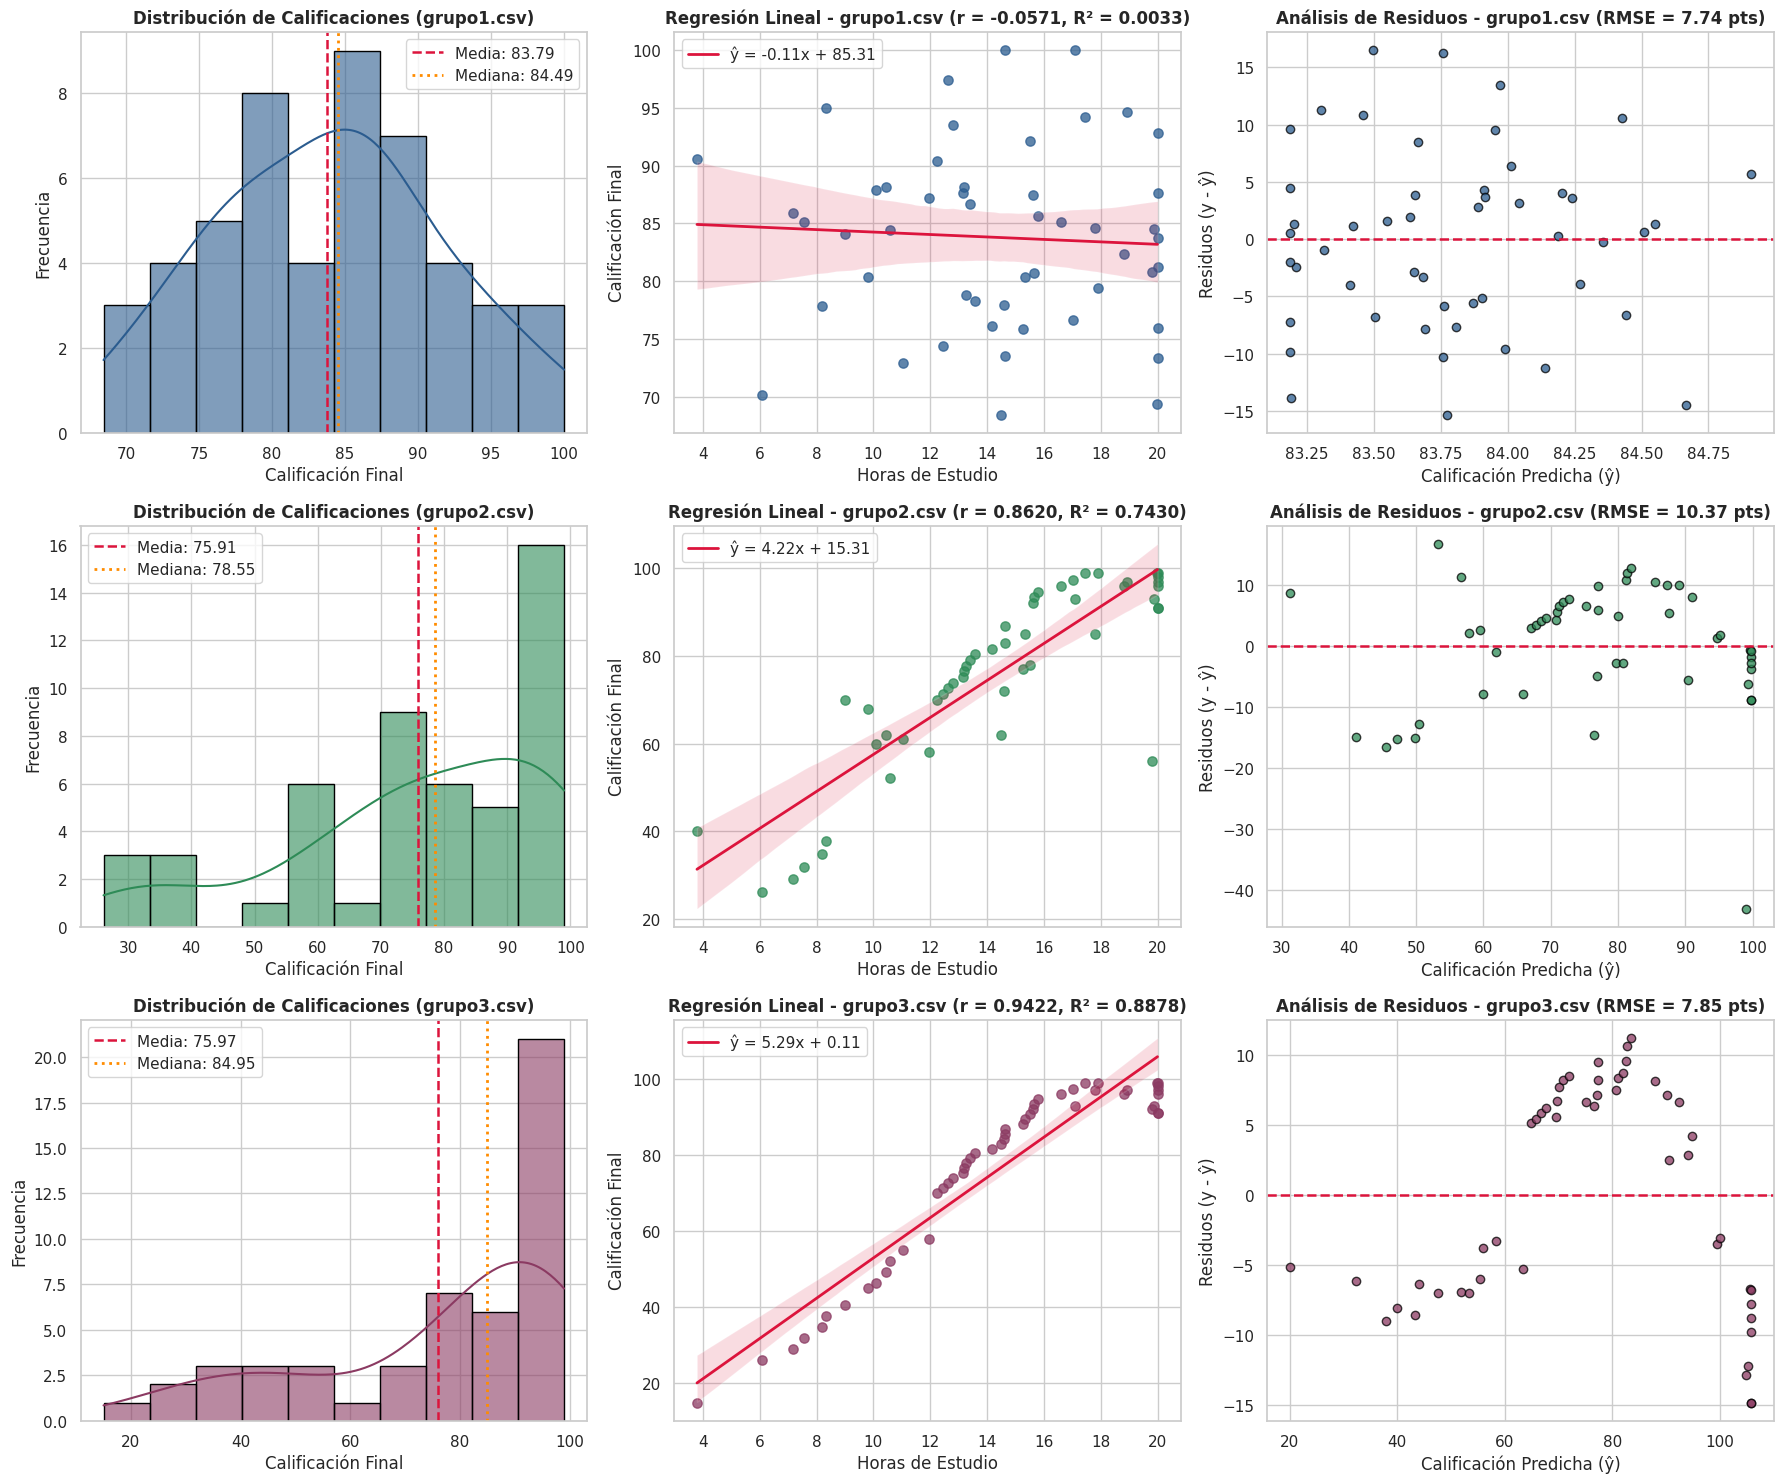

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
colores = ['#2b5c8f', '#2e8b57', '#8b3a62']

for idx, (archivo, df) in enumerate(datasets.items()):
    X = df[['HorasEstudio']]
    y = df['Calificacion']

    modelo = LinearRegression().fit(X, y)
    y_pred = modelo.predict(X)
    residuos = y - y_pred

    r, _ = stats.pearsonr(df['HorasEstudio'], y)
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))

    # Columna 1: Histograma + Curva de Densidad (KDE) + Media y Mediana
    sns.histplot(y, bins=10, kde=True, color=colores[idx], ax=axes[idx, 0], edgecolor='black', alpha=0.6)
    axes[idx, 0].axvline(y.mean(), color='crimson', linestyle='--', linewidth=1.8, label=f'Media: {y.mean():.2f}')
    axes[idx, 0].axvline(y.median(), color='darkorange', linestyle=':', linewidth=2, label=f'Mediana: {y.median():.2f}')
    axes[idx, 0].set_title(f'Distribución de Calificaciones ({archivo})', fontweight='bold')
    axes[idx, 0].set_xlabel('Calificación Final')
    axes[idx, 0].set_ylabel('Frecuencia')
    axes[idx, 0].legend()

    # Columna 2: Dispersión + Recta de Regresión + Intervalo de Confianza 95%
    sns.regplot(
        data=df, x='HorasEstudio', y='Calificacion', ax=axes[idx, 1],
        scatter_kws={'color': colores[idx], 'alpha': 0.75, 's': 45},
        line_kws={'color': 'crimson', 'linewidth': 2, 'label': f'ŷ = {modelo.coef_[0]:.2f}x + {modelo.intercept_:.2f}'}
    )
    axes[idx, 1].set_title(f'Regresión Lineal - {archivo} (r = {r:.4f}, R² = {r2:.4f})', fontweight='bold')
    axes[idx, 1].set_xlabel('Horas de Estudio')
    axes[idx, 1].set_ylabel('Calificación Final')
    axes[idx, 1].legend()

    # Columna 3: Gráfico de Residuos (Diagnóstico de linealidad y valores atípicos)
    axes[idx, 2].scatter(y_pred, residuos, color=colores[idx], alpha=0.75, edgecolor='black')
    axes[idx, 2].axhline(0, color='crimson', linestyle='--', linewidth=1.8)
    axes[idx, 2].set_title(f'Análisis de Residuos - {archivo} (RMSE = {rmse:.2f} pts)', fontweight='bold')
    axes[idx, 2].set_xlabel('Calificación Predicha (ŷ)')
    axes[idx, 2].set_ylabel('Residuos (y - ŷ)')

plt.tight_layout()
plt.show()

## Interpretación de Resultados

### 1. Interpretación del coeficiente de regresión (pendiente)
La pendiente nos dice cuántos puntos sube o baja la calificación en promedio por cada hora extra que un alumno dedica a estudiar:

* **Grupo 1 ($\hat{y} = -0.1061x + 85.3107$):** La pendiente es de $-0.11$, lo que en la práctica equivale a cero. Estudiar una hora más o una hora menos no cambia la calificación; los alumnos se mantienen alrededor de los $85.3$ puntos sin importar cuánto tiempo estudien.
* **Grupo 2 ($\hat{y} = 4.2227x + 15.3075$):** Por cada hora adicional de estudio, la calificación sube en promedio **$4.22$ puntos**, partiendo de una base teórica de $15.31$ puntos si no se estudia nada.
* **Grupo 3 ($\hat{y} = 5.2857x + 0.1081$):** Es donde más impacta el tiempo de estudio. Cada hora extra aumenta la calificación en **$5.29$ puntos** en promedio, arrancando prácticamente desde cero ($0.11$).

### 2. Interpretación del coeficiente de correlación ($r$)
El coeficiente de Pearson nos indica qué tan fuerte es la relación lineal entre las horas de estudio y la nota final, y si van en la misma dirección:

* **Grupo 1 ($r = -0.0571$):** No hay relación lineal. Los puntos en la gráfica están dispersos por todos lados: hay gente que estudió menos de $4$ horas y sacó más de $90$, y gente que estudió $20$ horas y sacó menos de $70$.
* **Grupo 2 ($r = 0.8620$):** Hay una correlación positiva fuerte. Mientras más horas estudian, mejor calificación obtienen. El coeficiente no es aún más alto porque hay un dato atípico muy marcado: un alumno que estudió $20$ horas pero sacó $56$.
* **Grupo 3 ($r = 0.9422$):** Presenta una correlación positiva muy fuerte. Casi todos los puntos siguen de cerca la línea ascendente, confirmando que a mayor tiempo de estudio, mayor calificación.

### 3. ¿El modelo de regresión lineal es estadísticamente significativo?
Evaluando los modelos con un nivel de significancia de $\alpha = 0.05$ (comparando contra la hipótesis nula de que la pendiente es cero):

* **Grupo 1:** **No es significativo.** El valor $p$ es $0.6935$ (muy por encima de $0.05$) y el intervalo de confianza de la pendiente va de $-0.64$ a $0.43$, pasando por el cero. La ligera inclinación hacia abajo de la recta es puro ruido estadístico.
* **Grupo 2:** **Sí es significativo.** El valor $p$ es de $9.08 \times 10^{-16}$ ($p < 0.05$), así que podemos asegurar que la relación entre horas de estudio y calificación no es casualidad.
* **Grupo 3:** **Sí es significativo.** Con un valor $p$ de $1.93 \times 10^{-24}$, la relación lineal entre ambas variables queda totalmente confirmada.

### 4. ¿Qué tan confiable es el modelo para predecir calificaciones?
Para saber qué tanto podemos confiar en las predicciones revisamos el coeficiente de determinación ($R^2$) y el error promedio ($\text{RMSE}$):

* **Grupo 1 ($R^2 = 0.0033$, $\text{RMSE} = 7.74$):** **No sirve para predecir.** El tiempo de estudio apenas explica el $0.33\%$ de la variación en las notas. Usar esta ecuación da el mismo resultado que simplemente adivinar el promedio del grupo ($83.79$).
* **Grupo 2 ($R^2 = 0.7430$, $\text{RMSE} = 10.37$):** **Es bastante confiable para tendencias generales.** Explica el $74.3\%$ de la variación en las calificaciones, aunque en casos individuales puede fallar por unos $\pm 10.4$ puntos debido a la dispersión y al alumno atípico de $20$ horas.
* **Grupo 3 ($R^2 = 0.8878$, $\text{RMSE} = 7.85$):** **Es muy confiable.** Explica el $88.8\%$ del comportamiento de las calificaciones. El único detalle a tomar en cuenta es que, como la calificación máxima es $100$, a partir de las $16$ horas de estudio los datos reales se topan con ese límite y la recta tiende a pasarse un poco del $100$.

### Conclusiones
Aunque los tres grupos tienen exactamente las mismas estadísticas en sus horas de estudio (un promedio de $14.35$ horas), el efecto sobre sus calificaciones es muy distinto. En los **Grupos 2 y 3** queda claro que dedicarle tiempo al estudio se refleja directamente en mejores notas, logrando modelos lineales significativos y útiles para predecir el rendimiento.

En cambio, el **Grupo 1** muestra que el tiempo de estudio no siempre es el único factor: todos sus alumnos aprobaron con calificaciones altas (entre $68.46$ y $100$) sin importar cuánto estudiaron, lo que apunta a que influyeron otras cosas como conocimientos previos o una evaluación más sencilla. Por último, revisar los residuos ayudó a notar que en el Grupo 3 la relación deja de ser totalmente recta cerca del $100$ por el límite propio de la escala de calificación.